In [1]:
set datafile columnheaders
set datafile separator comma
set ytics nomirror
set xtics nomirror
height = 1
width = 1
fn = "out"
fs = 16
data = "output/data/"
unset colorbox
set palette rgbformulae 33,13,10

In [2]:
%%reset
set terminal postscript enhanced eps size width*5,height*3 color
set output "output/plots/" . fn . ".ps"
replot
set terminal pngcairo size width*10inch,height*6inch
fn="out"

set terminal postscript enhanced eps size width*5,height*3 color

Terminal type is now 'postscript'
Options are 'eps enhanced defaultplex \
   leveldefault color colortext \
   dashlength 1.0 linewidth 1.0 pointscale 1.0 butt noclip \
   nobackground \
   palfuncparam 2000,0.003 \
    noadobeglyphnames \
   size 5.00in, 3.00in "Helvetica" 14  fontscale 1.0 '
replot
         ^
         no previous plot

set terminal pngcairo size width*10inch,height*6inch

Terminal type is now 'pngcairo'
Options are ' background "#ffffff" enhanced fontscale 1.0 size 10.00in, 6.00in '

# Favourite-longshot bias

## General

In [3]:
set key right bottom
set key auto columnheader noopaque
set style data lines
set xlabel "Implied Probability"
#set logscale x 2
#set xrange[1:1000]

In [4]:
width=1.5

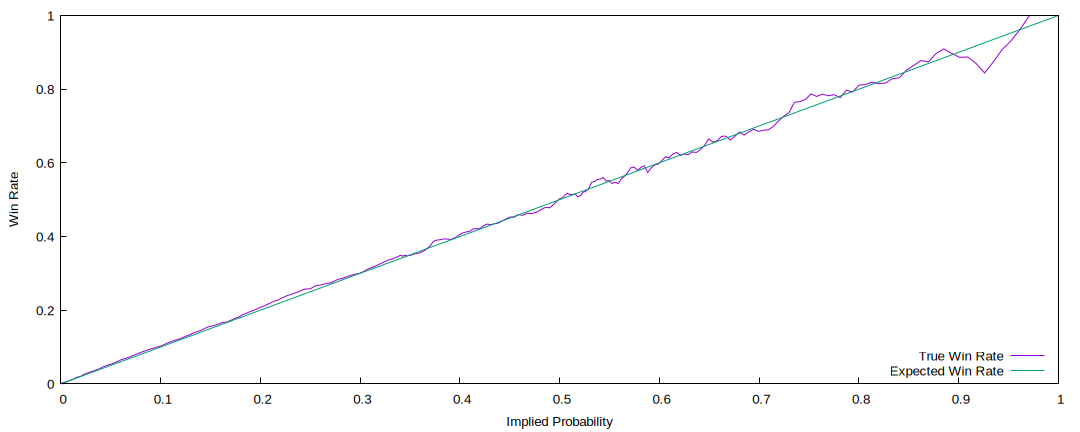

In [5]:
set ylabel "Win Rate"
plot data . 'all-fl.csv' using (1/column(1)):(column("mean")) title "True Win Rate", x title "Expected Win Rate"
fn="all-fl"

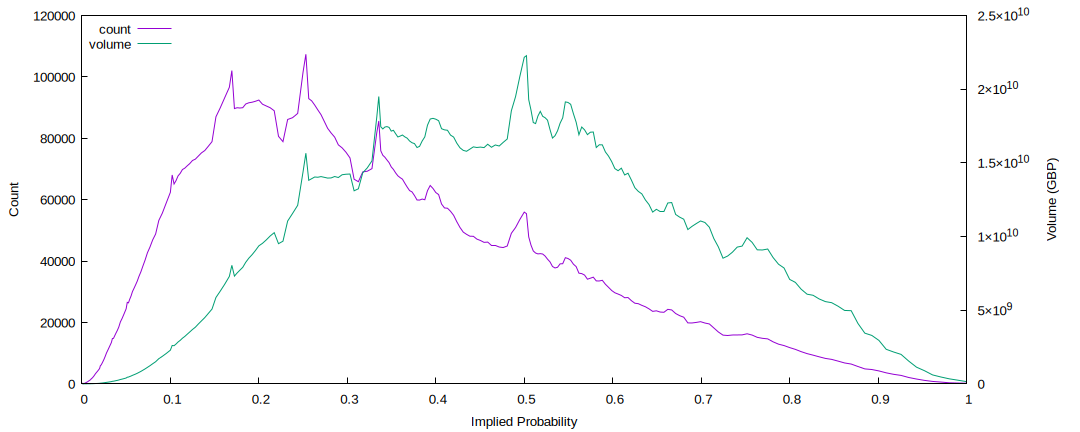

In [6]:
set key left top
set ylabel "Count"
set y2label "Volume (GBP)"
set y2tics
plot data . 'all-fl.csv' using (1/column(1)):(column("count")/column("tick_size")), '' using (1/column(1)):(column("volume")/column("tick_size")) axes x1y2
fn="all-count-vol"

In [7]:
unset y2label
unset y2tics

## Groupings

In [8]:
cats = "race_no distance_f hour race_type location nrunners ppvol overround"

In [9]:
fn="race_no"
#set key inside left bottom offset 1,0
#set key maxcols 3 maxrows 5
set key width 0
set key right bottom
set title "race number"
set style data lines
set tics nomirror
set border 31
unset margins
set xtics right

In [10]:
width=3
height=3

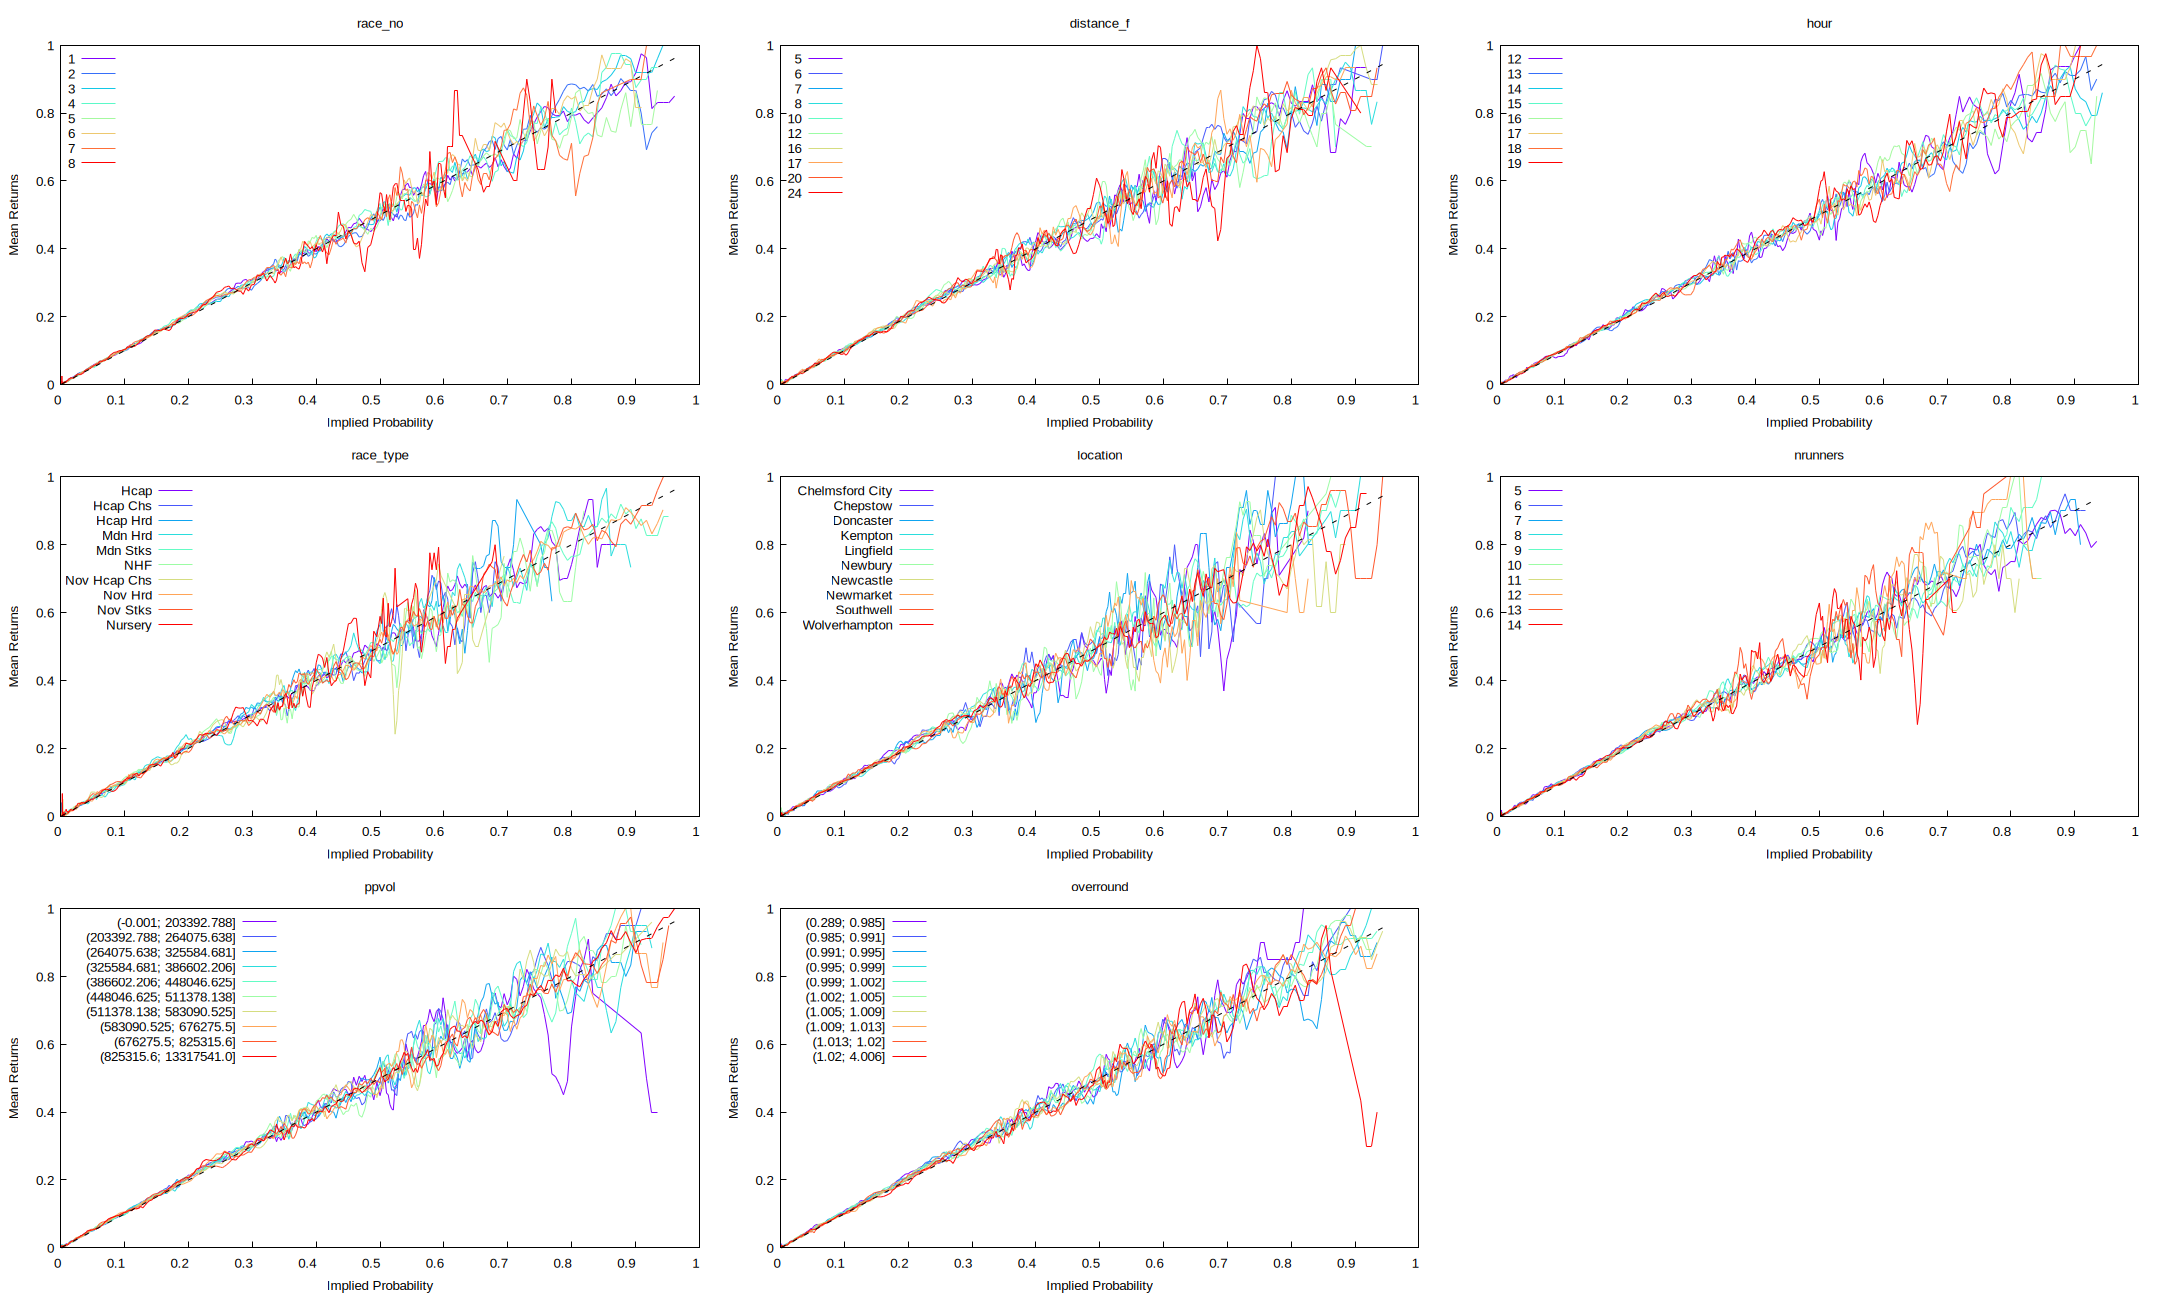

In [11]:
fn="groups-fl-mean"
set multiplot layout 3,3
set key left top
unset colorbox
set ylabel "Mean Returns"
do for [c in cats] {
    f = data . c . '-fl-mean.csv'
    set title (c) noenhanced
    plot for [COL=3:*] f using (1/column(1)):COL:(COL) lc palette, x lc "black" dt 2
}
unset multiplot

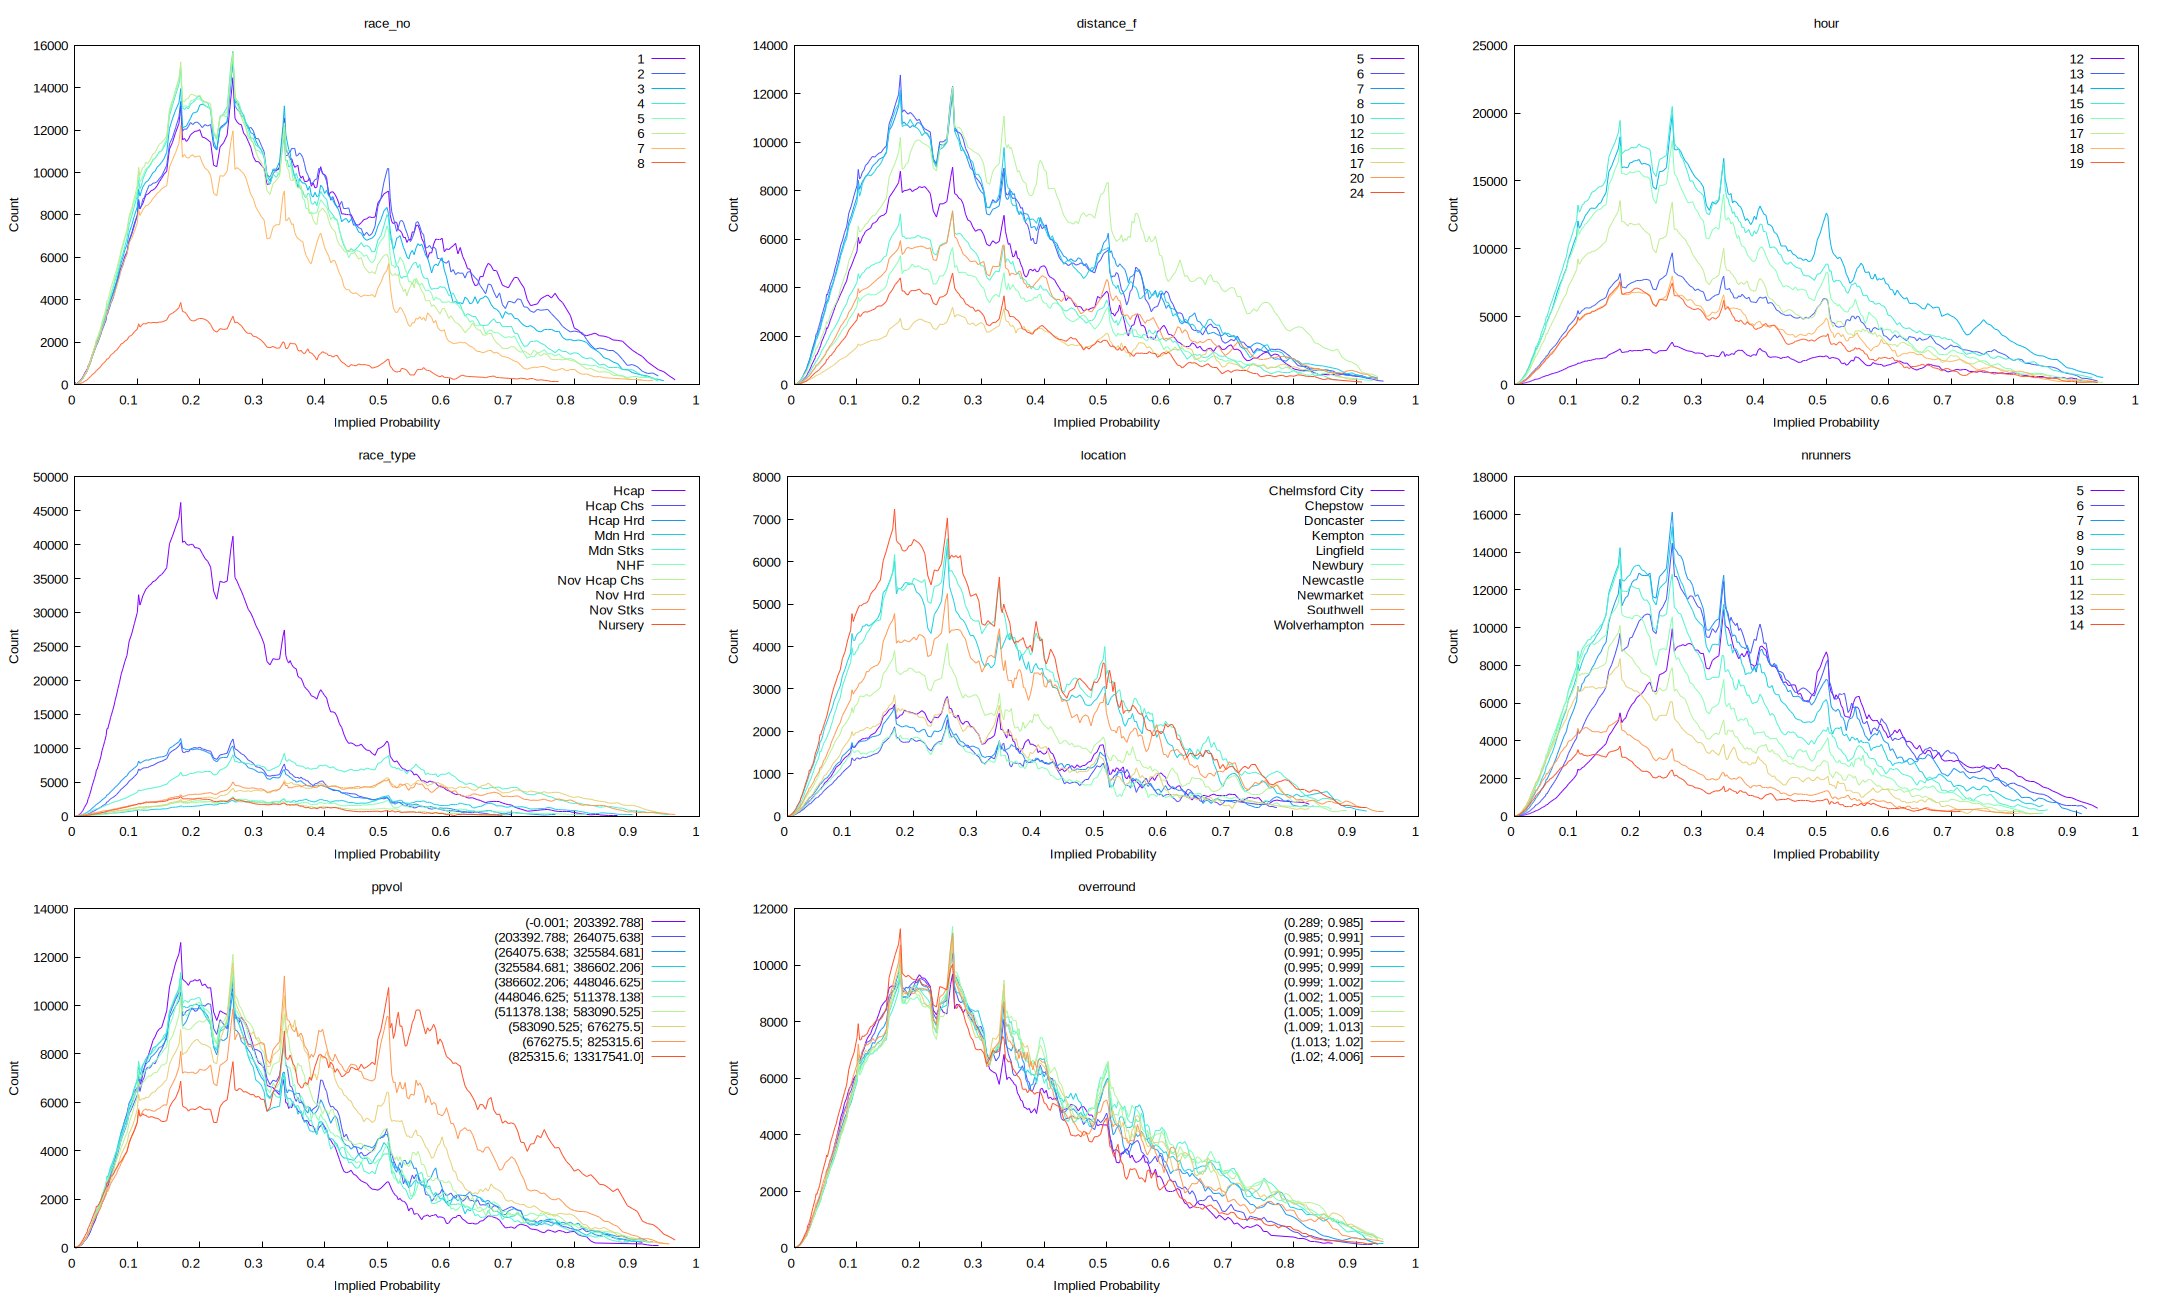

In [12]:
fn="groups-fl-count"
set key right top
set multiplot layout 3,3
unset colorbox
set ylabel "Count"
do for [c in cats] {
    f = data . c . '-fl-count.csv'
    set title (c) noenhanced
    plot for [COL=3:*] f using (1/column(1)):(column(COL)/column(2)):(COL) lc palette
}
unset multiplot

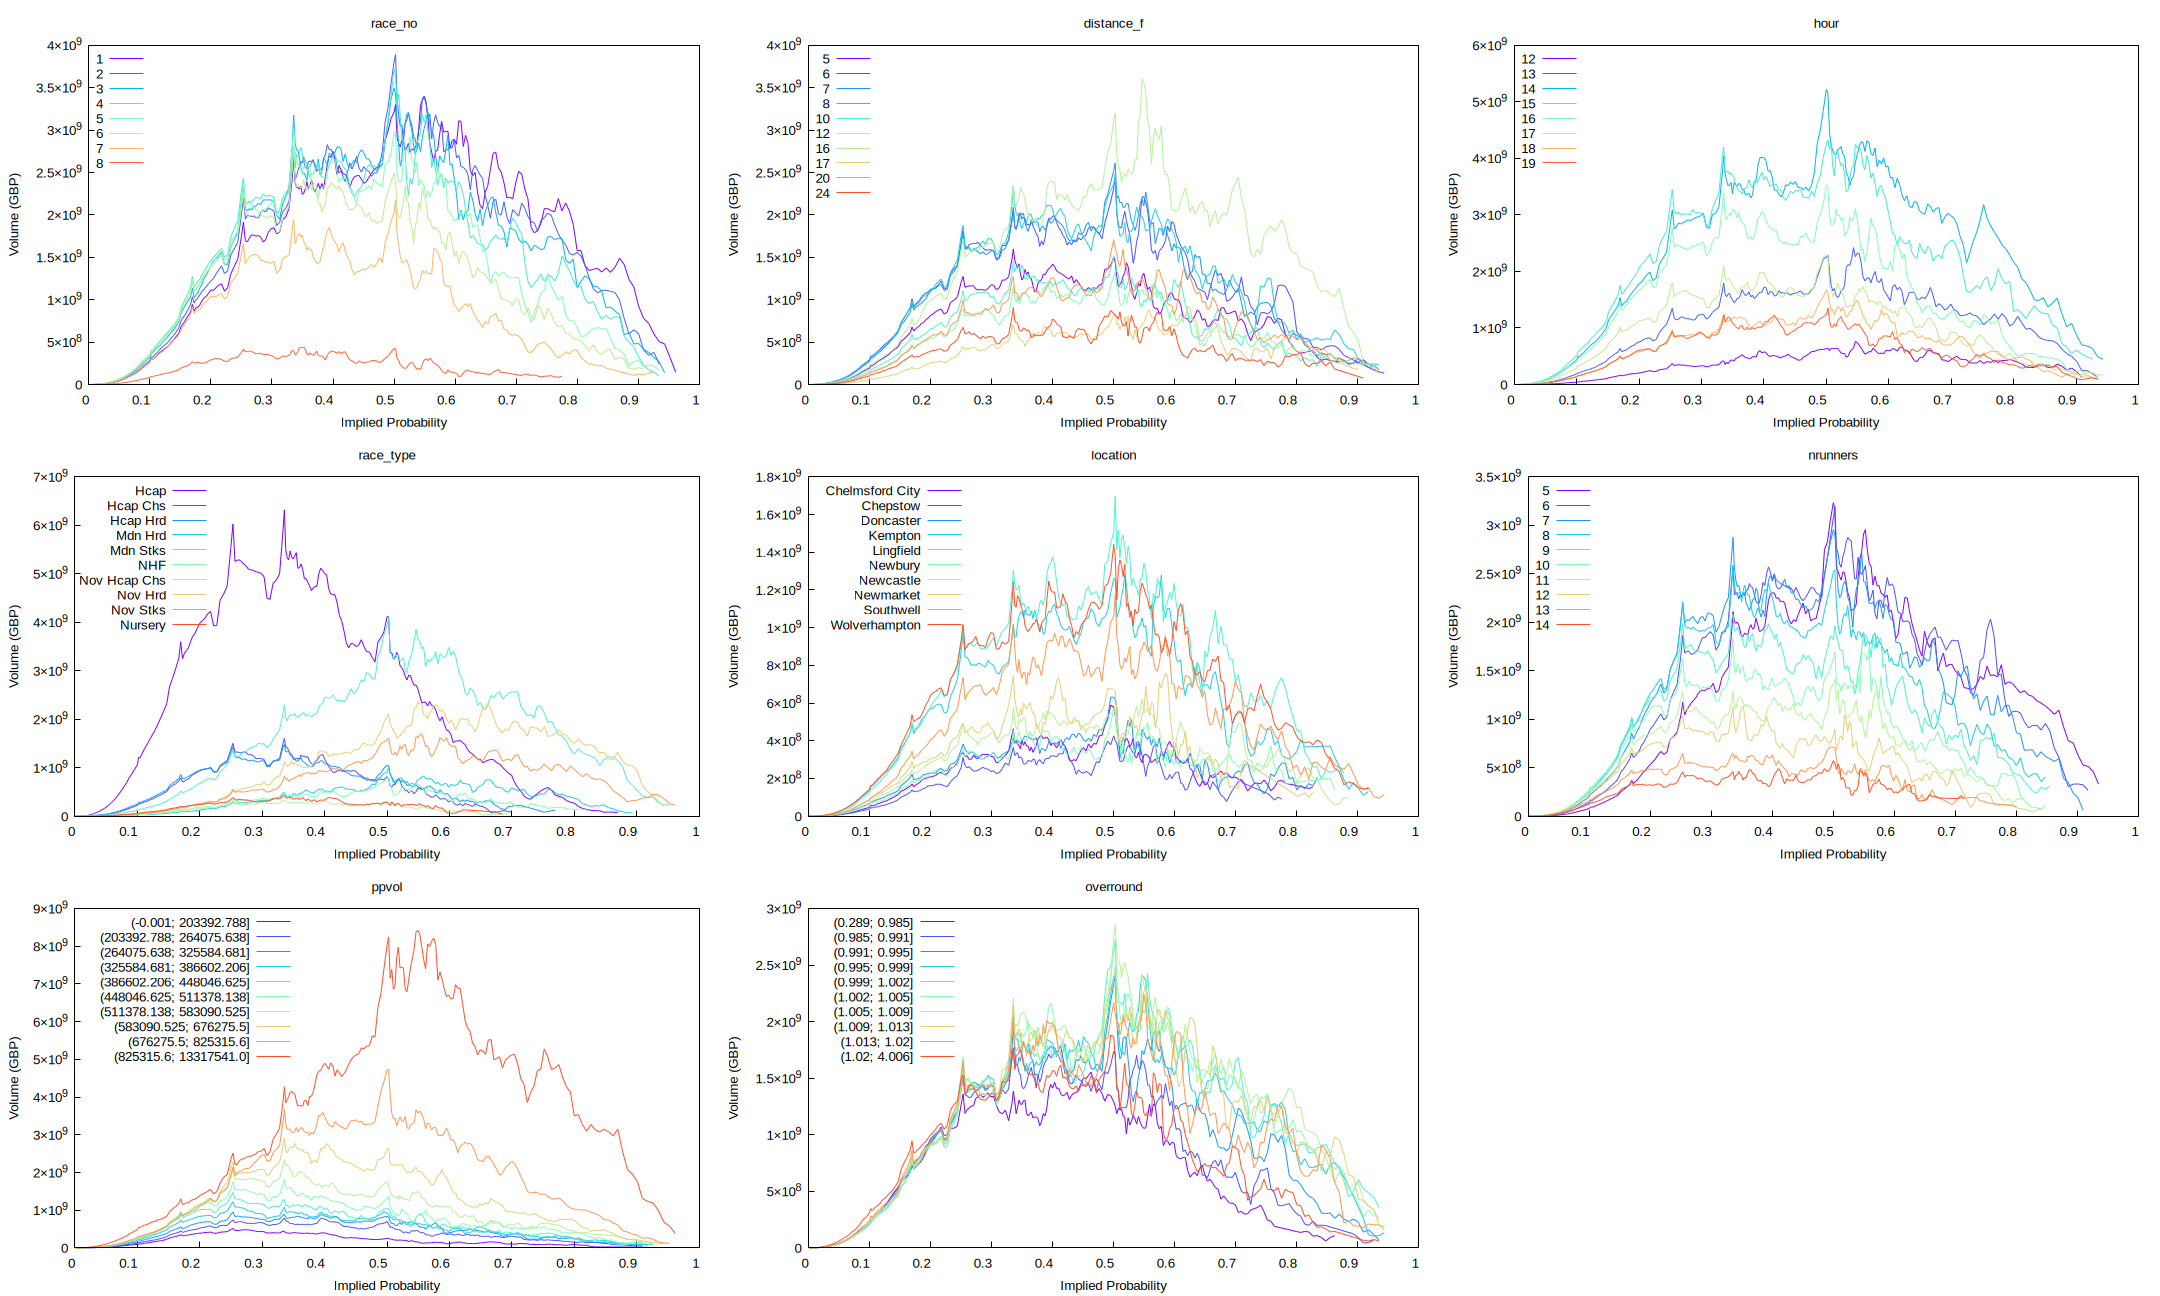

In [13]:
fn="groups-fl-vol"
set key left top
set multiplot layout 3,3
unset colorbox
set ylabel "Volume (GBP)"
do for [c in cats] {
    f = data . c . '-fl-sum.csv'
    set title (c) noenhanced
    plot for [COL=3:*] f using (1/column(1)):(column(COL)/column(2)):(COL) lc palette
}
unset multiplot

# Test Statistics

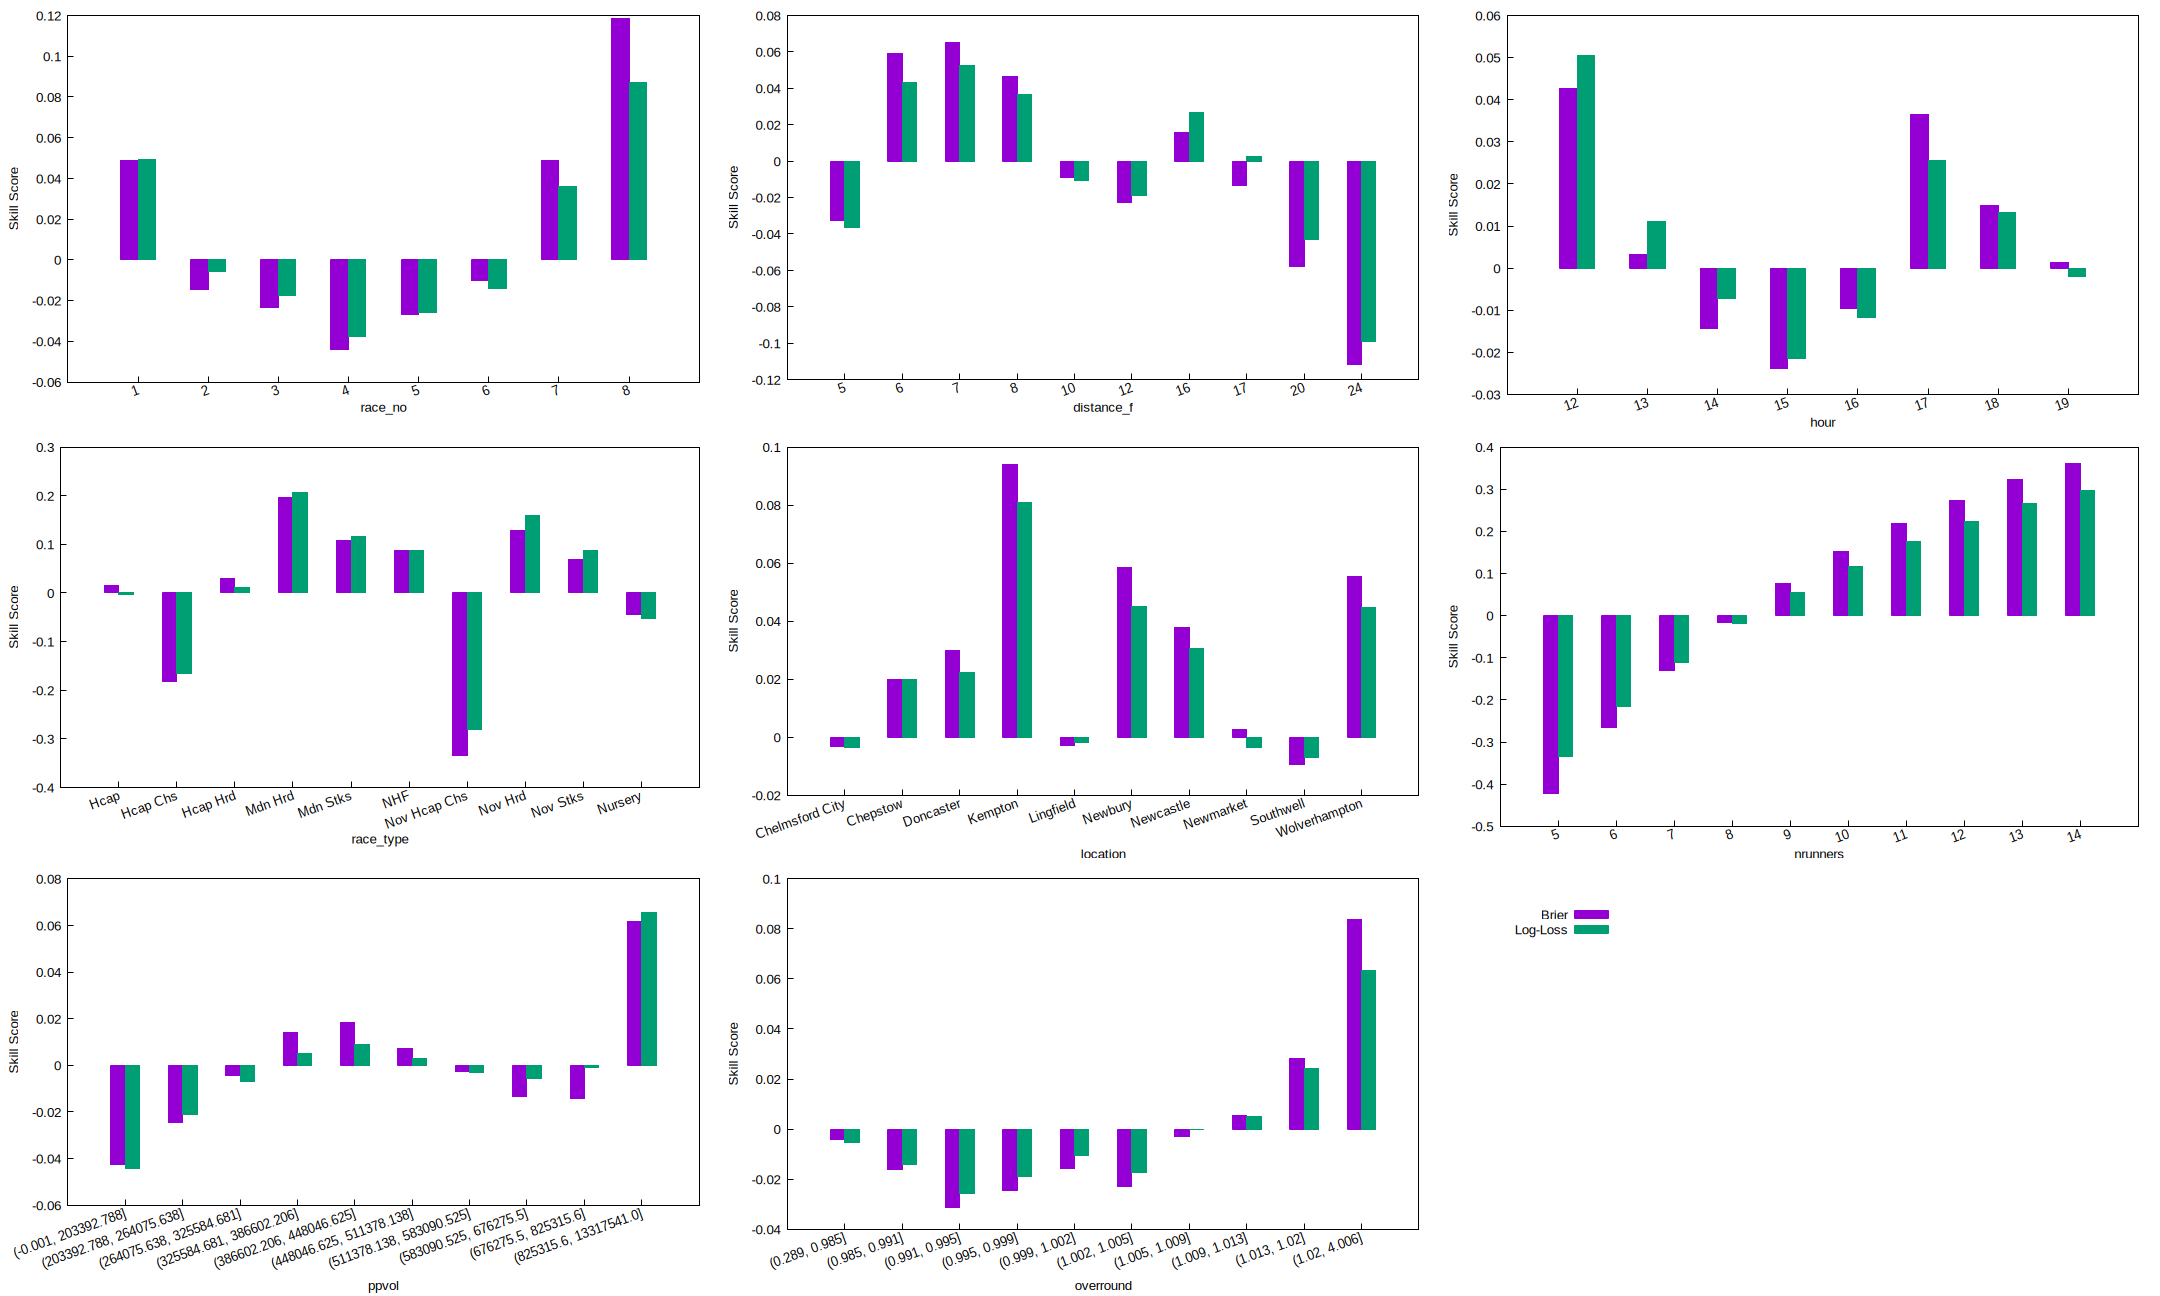

In [14]:
set style data histogram
set multiplot layout 3,3
fn="groups-acc"
set ylabel "Skill Score"
unset title
set xtics rotate by 20
set yrange [*:*]
set key at screen 0.7,0.3
set style fill solid
do for [c in cats] {
    f = data . c . '-acc.csv'
    set xlabel (c) noenhanced
    plot f using 2:xticlabels(1) title "Brier", '' using 3:xticlabels(1) title "Log-Loss"
    unset key
}
unset multiplot

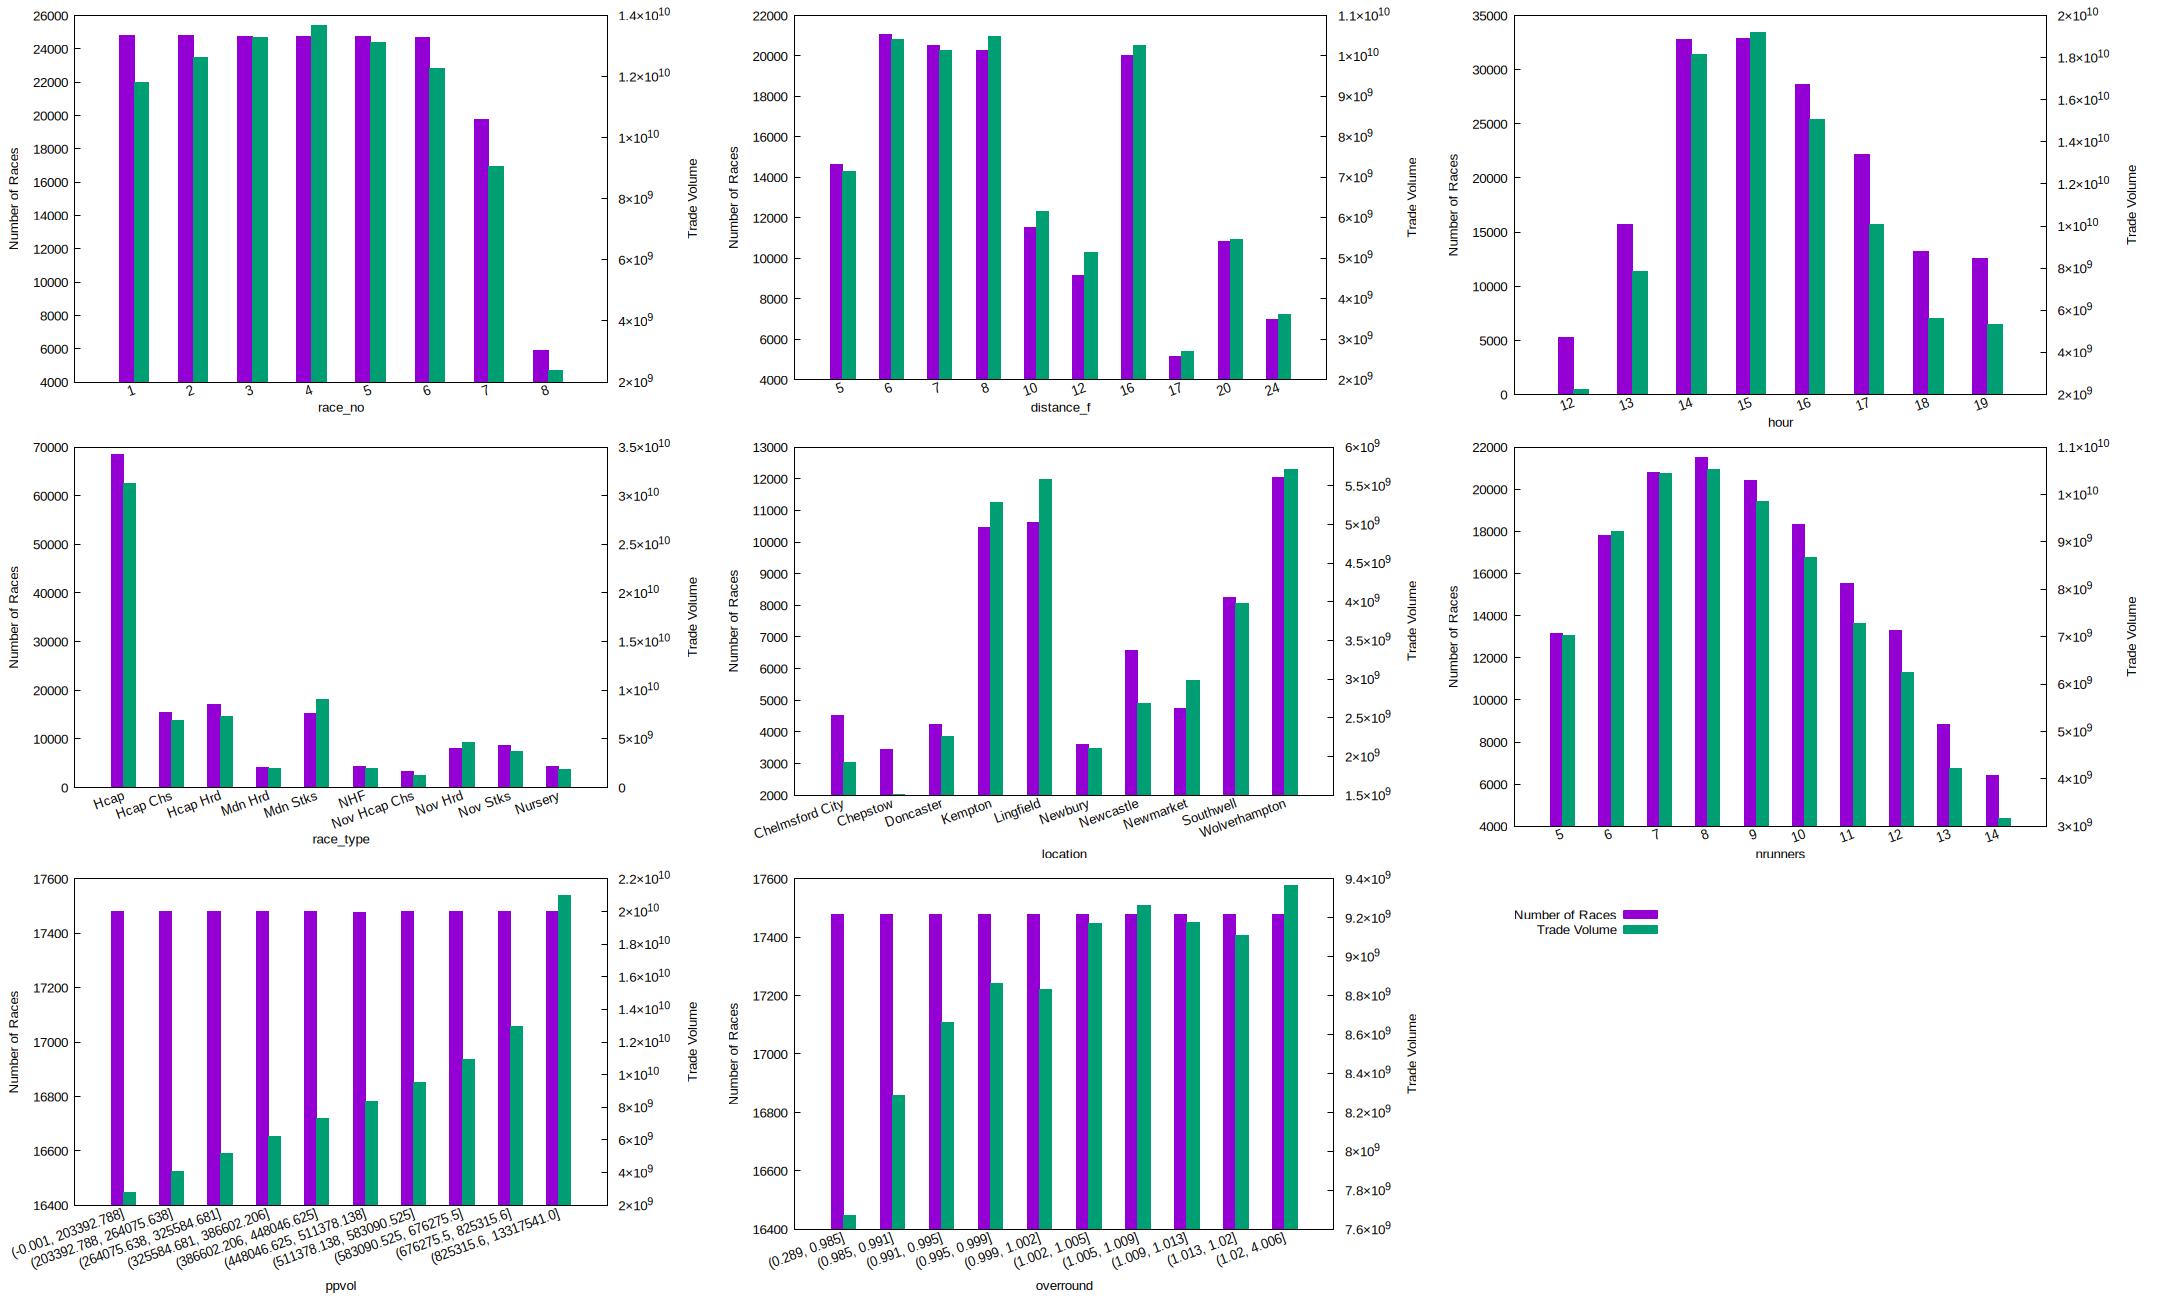

In [15]:
fn = 'groups-count'
set key
set multiplot layout 3,3
set ylabel "Number of Races"
set y2label "Trade Volume"
set y2tics
set offsets 0,0,0,1000
do for [c in cats] {
    f = data . c . '-acc.csv'
    set xlabel (c) noenhanced
    plot f using 4:xticlabels(1) title "Number of Races", '' using 5:xticlabels(1) axes x1y2 title "Trade Volume"
    unset key
}
unset multiplot

In [16]:
width = 1
height = 1

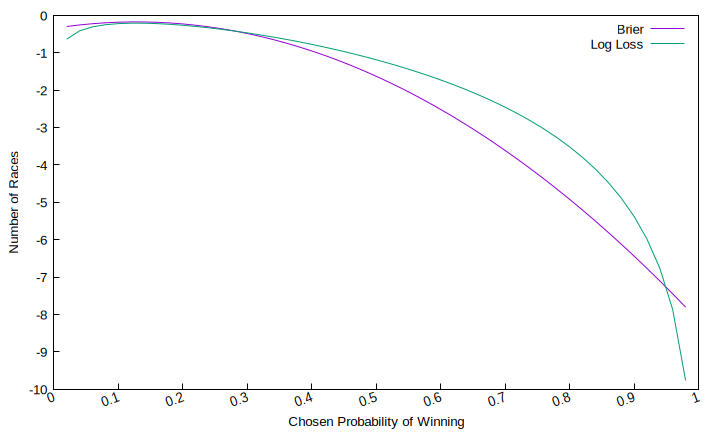

In [17]:
fn="all_ss_random"
unset offsets
unset y2label
unset y2tics
set style data lines
unset key
set key inside right top
set xlabel "Chosen Probability of Winning"
plot data . '/all_ss_random.csv' using 1:2 title "Brier", '' using 1:3 title "Log Loss"